# Robustez de redes: fallas aleatorias vs. ataques dirigidos

**Pregunta:** tres redes con el mismo número de nodos y el mismo número de conexiones, ¿se rompen igual cuando se les quitan nodos?

Este cuaderno recorre el experimento paso a paso. El código pesado vive en `src/robustez.py`.

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import networkx as nx
import robustez as rb

## 1. Tres redes, mismo tamaño, distinta regla

- **Erdős-Rényi:** cada par de nodos se conecta con la misma probabilidad. Grados concentrados alrededor de la media.
- **Watts-Strogatz:** un anillo donde cada nodo se conecta con sus vecinos cercanos, más unos pocos atajos al azar. Mucho agrupamiento.
- **Barabási-Albert:** los nodos nuevos prefieren conectarse con los que ya tienen muchas conexiones. Aparecen *hubs*.

In [2]:
gens = rb.generadores(N=2000, k_medio=6)
for nombre, gen in gens.items():
    G = gen(0)
    grados = np.array([d for _, d in G.degree()])
    print(f"{nombre:16s} grado medio {grados.mean():.2f}   grado máximo {grados.max():4d}   "
          f"agrupamiento {nx.average_clustering(G):.3f}")

Erdős-Rényi      grado medio 5.99   grado máximo   16   agrupamiento 0.003
Watts-Strogatz   grado medio 6.00   grado máximo    9   agrupamiento 0.445
Barabási-Albert  grado medio 5.99   grado máximo  176   agrupamiento 0.021


Mismo grado medio, pero el nodo más conectado de Barabási-Albert tiene muchísimas más conexiones que el de las otras dos. Esa diferencia en la **cola** de la distribución es lo que decide todo lo que sigue.

## 2. La medida: la componente gigante

Se quitan nodos uno a uno y se mide qué fracción de la red original sigue en el pedazo conectado más grande, $S$. Cuando $S$ cae a casi cero, la red dejó de funcionar como un todo: es una **transición de fase** (percolación).

Dos formas de quitar nodos:
- **Fallas:** al azar.
- **Ataque:** primero los más conectados.

### Truco de eficiencia (Newman-Ziff)
Recalcular la componente gigante después de cada remoción costaría ~$N^2$ operaciones. En cambio se recorre la película al revés: se arranca con la red vacía, se *agregan* nodos en orden inverso y se van fusionando clusters con una estructura *union-find*. Casi lineal en $N$. Las pruebas en `tests/` verifican que da exactamente lo mismo que la fuerza bruta.

In [3]:
rng = np.random.default_rng(1)
G = gens["Barabási-Albert"](1)
S_fallas = rb.curva_componente_gigante(G, rb.orden_aleatorio(G, rng))
S_ataque = rb.curva_componente_gigante(G, rb.orden_por_grado(G, rng))
for f in (0.1, 0.2, 0.3, 0.5):
    j = int(f * G.number_of_nodes())
    print(f"quitando {f:.0%}:   fallas S = {S_fallas[j]:.2f}   ataque S = {S_ataque[j]:.2f}")

quitando 10%:   fallas S = 0.90   ataque S = 0.84
quitando 20%:   fallas S = 0.80   ataque S = 0.57
quitando 30%:   fallas S = 0.69   ataque S = 0.03
quitando 50%:   fallas S = 0.46   ataque S = 0.00


## 3. La teoría

Para una red aleatoria con distribución de grados $p_k$, la componente gigante existe mientras

$$\kappa = \frac{\langle k^2 \rangle}{\langle k \rangle} > 2 \quad\text{(criterio de Molloy-Reed)}$$

y quitando nodos al azar se destruye al pasar la fracción crítica (Cohen et al., 2000)

$$f_c = 1 - \frac{1}{\kappa - 1}.$$

La clave está en $\langle k^2\rangle$: los hubs la inflan muchísimo, así que $f_c$ se acerca a 1. En el límite de una ley de potencia con exponente menor que 3 y $N\to\infty$, $\langle k^2\rangle$ diverge y **ninguna** fracción de fallas aleatorias rompe la red.

In [4]:
for nombre, gen in gens.items():
    p = rb.distribucion_grados(gen(0))
    print(f"{nombre:16s} kappa = {rb.parametro_kappa(p):6.2f}   f_c teórico = {rb.fraccion_critica_aleatoria(p):.3f}")

Erdős-Rényi      kappa =   6.99   f_c teórico = 0.833
Watts-Strogatz   kappa =   6.10   f_c teórico = 0.804
Barabási-Albert  kappa =  16.33   f_c teórico = 0.935


## 4. Experimento completo

`src/experimento.py` repite todo con 30 redes independientes por familia y guarda figuras y tabla.

In [5]:
import subprocess
print(subprocess.run([sys.executable, str(RAIZ / "src" / "experimento.py")],
                     capture_output=True, text=True, cwd=RAIZ).stdout)

            red  kappa  grado_max_medio  fc_teoria_fallas  fc_sim_fallas  fc_sim_fallas_sd  fc_sim_ataque  fc_sim_ataque_sd
    Erdős-Rényi  7.005           16.500             0.833          0.798             0.014          0.537             0.017
 Watts-Strogatz  6.095            9.367             0.804          0.659             0.021          0.503             0.035
Barabási-Albert 15.494          135.300             0.931          0.836             0.020          0.275             0.011

Tiempo total: 18.9 s



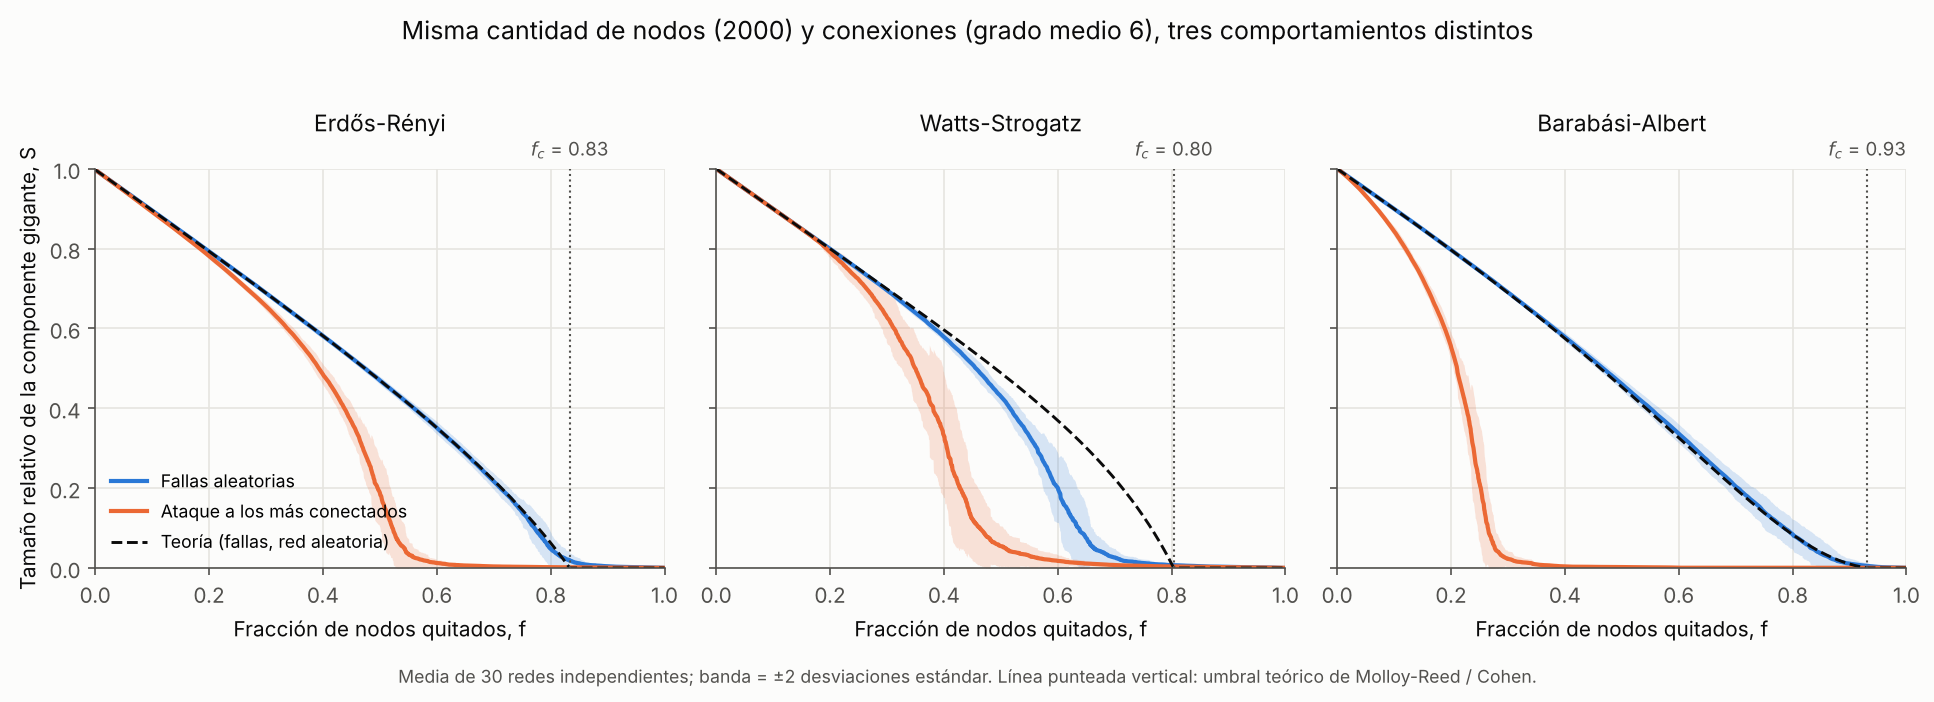

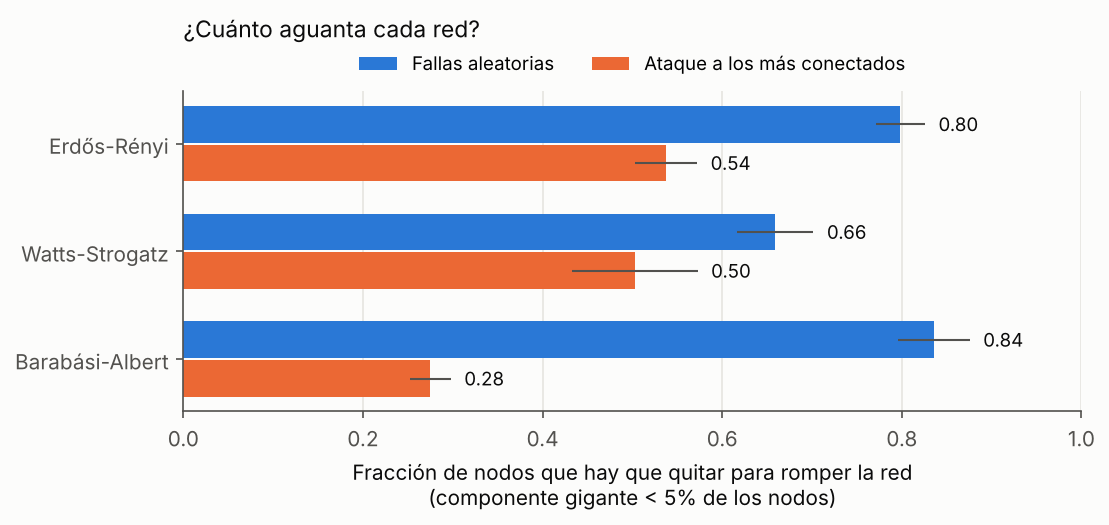

In [6]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figures" / "curvas_robustez.png")))
display(Image(filename=str(RAIZ / "figures" / "umbrales.png")))

## 5. Lectura

1. **Erdős-Rényi:** la teoría acierta casi perfecto. Atacar los más conectados ayuda, pero no tanto, porque no hay nodos muy distintos al promedio.
2. **Watts-Strogatz:** se rompe **antes** de lo que dice la teoría. La teoría supone una red sin agrupamiento; aquí los vecinos de un nodo están conectados entre sí, así que muchas conexiones son redundantes y no ayudan a mantener unida la red global.
3. **Barabási-Albert:** la paradoja. Es la más resistente a fallas aleatorias y la más frágil ante ataques: quitar ~28 % de los nodos (los hubs) basta para destruirla, contra ~84 % al azar.

**Moraleja:** el grado medio no dice nada sobre la robustez. Lo que importa es la forma de la distribución, y sobre todo su cola.